> **⚠️ OUTDATED (2026-07-16) — xem trước khi chạy lại**
>
> Notebook này hiển thị `alpha_score` cùng các cột `momentum_score`/`rs_score`/`trend_score`/`liquidity_score`
> như thể `alpha_score` được dẫn dắt bởi các nhân tố đó (tư duy v1). Từ `docs/reports/scoring/SCORE_V2_REPORT.md`, `alpha_score`
> hiện tại (v2) chỉ là 70% `realized_vol_20d` + 30% `value_ma20` — các cột momentum/trend/rs ở đây thuộc về
> `alpha_score_shadow_v1` (composite cũ, giữ lại để so sánh, không phải cơ sở của `alpha_score`).
>
> Xem thêm: `docs/reports/scoring/SCORE_V2_REPORT.md` mục "Trạng thái sau GĐ5" (v2 hiện chỉ chạy shadow, KHÔNG dùng vốn thật) và
> `docs/reports/scoring/WATCHLIST_VALIDATION_REPORT.md` (composite/`risk_score` đã kiểm định, kết quả âm tính/trùng lặp).
>
> **Không sửa nội dung notebook trong round này** — chỉ cảnh báo trước khi dùng lại kết quả.

# 12 — Meta Ranking & Alpha Scoring

Notebook này kết hợp các tín hiệu và điểm số để xếp hạng danh mục cổ phiếu tiềm năng.

In [1]:
# Cell: Setup Project Root
import os
from pathlib import Path
import sys


def find_project_root(start_path=None):
    path = Path(start_path or os.getcwd()).resolve()
    for parent in [path, *path.parents]:
        if (parent / "src").is_dir() and (parent / "config").is_dir():
            return parent
    raise FileNotFoundError("Khong tim thay project root co thu muc src/ va config/")


# Previous version assumed cwd was either already the project root or named
# exactly "notebooks" -- broke under nbconvert (cwd = the notebook's own
# subdirectory, e.g. "03_alpha_signals") with ModuleNotFoundError: No module
# named 'src' (docs/reports/codebase_audit/NOTEBOOK_AUDIT_FULL.md NV2). Now
# searches upward for src/+config/, same helper used by every other notebook.
PROJECT_ROOT = find_project_root()
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROJECT_ROOT


PosixPath('/Users/jamesb/Desktop/vietnam-quant-research')

In [2]:
# Cell: Import Meta Ranking Helpers
from pathlib import Path

import numpy as np
import pandas as pd

from src.analytics.meta_ranking import build_meta_ranking, top_meta_candidates, save_meta_ranking_outputs
from src.data.loaders import read_parquet
from src.reporting.chart_factory import (
    meta_component_heatmap,
    meta_priority_bucket_chart,
    meta_score_bar_chart,
    meta_symbol_component_chart,
)
from src.screening.light_market_scan import load_auto_watchlist_symbols


In [3]:
# Cell: Load Meta Inputs
features_path = Path("data/signals/setup_signals.parquet")
trade_cards_path = Path("data/signals/breakout_20d_trade_cards.parquet")
stealth_path = Path("data/signals/stealth_accumulation_latest.parquet")

features = read_parquet(features_path)
trade_cards = read_parquet(trade_cards_path)
stealth_latest = read_parquet(stealth_path)

feature_symbol_set = set(features["symbol"].astype(str).str.upper()) if not features.empty and "symbol" in features.columns else set()
trade_symbol_set = set(trade_cards["symbol"].astype(str).str.upper()) if not trade_cards.empty and "symbol" in trade_cards.columns else set()
stealth_symbol_set = set(stealth_latest["symbol"].astype(str).str.upper()) if not stealth_latest.empty and "symbol" in stealth_latest.columns else set()

diagnostic = {
    "features_symbols": int(features["symbol"].nunique()) if "symbol" in features.columns and not features.empty else 0,
    "trade_card_symbols": int(trade_cards["symbol"].nunique()) if "symbol" in trade_cards.columns and not trade_cards.empty else 0,
    "stealth_symbols": int(stealth_latest["symbol"].nunique()) if "symbol" in stealth_latest.columns and not stealth_latest.empty else 0,
}
print(diagnostic)


{'features_symbols': 500, 'trade_card_symbols': 500, 'stealth_symbols': 2}


In [4]:
# Cell: Build Meta Ranking
ranked = build_meta_ranking(
    features,
    trade_cards,
    stealth_latest,
    signal_col="breakout_20d",
)
watchlist = top_meta_candidates(ranked, top_n=20, min_score=50.0)
prime = top_meta_candidates(
    ranked,
    top_n=10,
    min_score=75.0,
)

print({
    "ranked_rows": len(ranked),
    "watchlist_symbols": int(watchlist["symbol"].nunique()) if not watchlist.empty else 0,
    "prime_symbols": int(prime["symbol"].nunique()) if not prime.empty else 0,
})


{'ranked_rows': 500, 'watchlist_symbols': 20, 'prime_symbols': 10}


In [5]:
# Cell: Review Top Candidates
review_cols = [
    col
    for col in [
        "meta_rank",
        "symbol",
        "meta_score",
        "priority_bucket",
        "setup_style",
        "trade_edge_score",
        "net_accumulation_score",
        "momentum_component_score",
        "risk_penalty_score",
        "meta_summary",
    ]
    if col in ranked.columns
]
display(ranked[review_cols].head(10))
display(watchlist[review_cols].head(10))

,meta_rank,symbol,meta_score,priority_bucket,setup_style,trade_edge_score,net_accumulation_score,momentum_component_score,risk_penalty_score,meta_summary
0,8,BBC,100.0,Prime Candidate,Momentum-led,45,0.0,94.600002,33.0,"BBC: meta score 100.0/100, phong cách Momentum..."
1,1,AMD,100.0,Prime Candidate,Developing / Mixed,0,0.0,19.285041,33.0,"AMD: meta score 100.0/100, phong cách Developi..."
2,2,APT,100.0,Prime Candidate,Developing / Mixed,0,0.0,7.751081,33.0,"APT: meta score 100.0/100, phong cách Developi..."
3,3,ARM,100.0,Prime Candidate,Momentum-led,0,0.0,81.924336,33.0,"ARM: meta score 100.0/100, phong cách Momentum..."
4,4,ART,100.0,Prime Candidate,Developing / Mixed,0,0.0,9.950265,33.0,"ART: meta score 100.0/100, phong cách Developi..."
5,5,ASA,100.0,Prime Candidate,Momentum-led,0,0.0,99.757301,33.0,"ASA: meta score 100.0/100, phong cách Momentum..."
6,6,ATG,100.0,Prime Candidate,Momentum-led,0,0.0,67.741098,33.0,"ATG: meta score 100.0/100, phong cách Momentum..."
7,7,ATS,100.0,Prime Candidate,Momentum-led,0,0.0,89.092536,33.0,"ATS: meta score 100.0/100, phong cách Momentum..."
8,9,BTT,100.0,Prime Candidate,Momentum-led,0,0.0,82.993787,33.0,"BTT: meta score 100.0/100, phong cách Momentum..."
9,10,GTA,100.0,Prime Candidate,Momentum-led,0,0.0,69.082810,33.0,"GTA: meta score 100.0/100, phong cách Momentum..."


,meta_rank,symbol,meta_score,priority_bucket,setup_style,trade_edge_score,net_accumulation_score,momentum_component_score,risk_penalty_score,meta_summary
0,8,BBC,100.0,Prime Candidate,Momentum-led,45,0.0,94.600002,33.0,"BBC: meta score 100.0/100, phong cách Momentum..."
1,1,AMD,100.0,Prime Candidate,Developing / Mixed,0,0.0,19.285041,33.0,"AMD: meta score 100.0/100, phong cách Developi..."
2,2,APT,100.0,Prime Candidate,Developing / Mixed,0,0.0,7.751081,33.0,"APT: meta score 100.0/100, phong cách Developi..."
3,3,ARM,100.0,Prime Candidate,Momentum-led,0,0.0,81.924336,33.0,"ARM: meta score 100.0/100, phong cách Momentum..."
4,4,ART,100.0,Prime Candidate,Developing / Mixed,0,0.0,9.950265,33.0,"ART: meta score 100.0/100, phong cách Developi..."
5,5,ASA,100.0,Prime Candidate,Momentum-led,0,0.0,99.757301,33.0,"ASA: meta score 100.0/100, phong cách Momentum..."
6,6,ATG,100.0,Prime Candidate,Momentum-led,0,0.0,67.741098,33.0,"ATG: meta score 100.0/100, phong cách Momentum..."
7,7,ATS,100.0,Prime Candidate,Momentum-led,0,0.0,89.092536,33.0,"ATS: meta score 100.0/100, phong cách Momentum..."
8,9,BTT,100.0,Prime Candidate,Momentum-led,0,0.0,82.993787,33.0,"BTT: meta score 100.0/100, phong cách Momentum..."
9,10,GTA,100.0,Prime Candidate,Momentum-led,0,0.0,69.082810,33.0,"GTA: meta score 100.0/100, phong cách Momentum..."


In [6]:
# Cell: Visualize Meta Leaders
meta_score_bar_chart(ranked, top_n=10, title="Top 10 Unified Meta Ranking Names")

In [7]:
# Cell: Review Bucket Distribution
meta_priority_bucket_chart(ranked, title="Meta Ranking Bucket Distribution")

In [8]:
# Cell: Compare Score Components
meta_component_heatmap(ranked, top_n=10, title="Meta Ranking Component Heatmap")

In [9]:
# Cell: Inspect Single Symbol Breakdown
focus_symbol = ranked.iloc[0]["symbol"] if not ranked.empty else "MBB"
print("focus_symbol:", focus_symbol)
meta_symbol_component_chart(ranked, symbol=focus_symbol, title="Meta Component Breakdown")

focus_symbol: BBC


In [ ]:
# Cell: Save Meta Ranking Outputs
# data/signals/meta_ranking*.parquet is owned by scripts/run_meta_ranking.py
# (step 7/7 of the nightly pipeline). Same reasoning as the alpha_scores cell
# below -- see AUDIT_NOTEBOOKS_REPORT.md OPEN_AUTO #2.
save_meta_ranking_outputs(ranked, out_dir="notebooks/outputs")
print("Saved notebook copies of meta ranking outputs to notebooks/outputs/")
print("Pipeline versions under data/signals/ left untouched -- regenerate with "
      "`python scripts/run_meta_ranking.py`.")

---
# Part 2 — Multi-Factor Alpha Research & Scoring System

Dưới đây là phần phân tích chấm điểm Alpha đa nhân tố (Multi-Factor Alpha Scoring) so với chỉ số VNINDEX, tính toán Rolling Beta và trực quan hóa hiệu quả sinh lời vượt trội.

# 12b — Alpha Research & Scoring System

Notebook này thực hiện tính toán điểm Alpha đa nhân tố (Multi-Factor Alpha Score) xếp hạng toàn bộ các mã cổ phiếu trên thị trường chứng khoán Việt Nam hàng ngày.

In [11]:
# Cell: Import Alpha Scoring Modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.data.loaders import read_parquet, save_parquet
from src.alpha.scoring import calculate_alpha_scores

In [12]:
# Cell: Load Inputs
# CUSTOMIZABLE: Define your custom watchlist here to filter alpha scoring analysis, or leave as None for full universe
user_watchlist = None  # e.g., ["SSI", "HPG", "FPT", "VIC"]
stock_df = read_parquet("data/processed/stock_features.parquet")
benchmark_df = read_parquet("data/processed/benchmark_vnindex.parquet")
if user_watchlist is not None:
    watchlist_upper = [sym.upper() for sym in user_watchlist]
    stock_df = stock_df[stock_df["symbol"].str.upper().isin(watchlist_upper)].copy()
    print(f"Using user custom watchlist for analysis: {watchlist_upper}")
print("Stock features rows:", len(stock_df))
print("Benchmark rows:", len(benchmark_df))

Stock features rows: 718709
Benchmark rows: 1634


In [ ]:
# Cell: Compute Alpha Scores
# data/signals/alpha_scores.parquet is owned by scripts/run_alpha_scoring.py
# (step 3/7 of the nightly pipeline) and read back by run_meta_ranking.py
# (step 7/7), final_watchlist.py and main_visual_dashboard.py. Writing it from
# here replaced the pipeline's version -- including the alpha_score_shadow_v1
# column this notebook never computes -- until the next nightly run happened to
# overwrite it back (AUDIT_NOTEBOOKS_REPORT.md OPEN_AUTO #2).
#
# save_parquet() now refuses pipeline-owned paths when running in a notebook
# kernel, so this write is redirected rather than merely blocked.
print("Computing cross-sectional alpha scores...")
scored = calculate_alpha_scores(stock_df, benchmark_df)
save_parquet(scored, "notebooks/outputs/alpha_scores.parquet")
print("Saved notebook copy to notebooks/outputs/alpha_scores.parquet")
print("Pipeline version at data/signals/alpha_scores.parquet left untouched.")

In [14]:
# Cell: Compute Rolling Beta to Benchmark
from src.analytics.advanced import compute_rolling_beta

print("Computing rolling beta for all assets...")
scored_with_beta = compute_rolling_beta(scored, benchmark_df, window=60)
print("Beta calculation complete.")

Computing rolling beta for all assets...
Beta calculation complete.


In [15]:
# Cell: Show Latest Top Alpha Ranked Stocks with Beta
latest_date = scored_with_beta["date"].max()
latest_subset = scored_with_beta[scored_with_beta["date"] == latest_date].copy()

cols = [
    "symbol", "date", "close", "alpha_score", "momentum_score", 
    "rs_score", "trend_score", "volume_score", "volatility_score", 
    "liquidity_score", "rolling_beta_60d", "market_regime"
]
available_cols = [c for c in cols if c in latest_subset.columns]

ranking = latest_subset[available_cols].sort_values("alpha_score", ascending=False)
print(f"Latest date in database: {latest_date.strftime('%Y-%m-%d') if hasattr(latest_date, 'strftime') else latest_date}")
display(ranking.head(20))

Latest date in database: 2026-07-22


,symbol,date,close,alpha_score,momentum_score,rs_score,trend_score,volume_score,volatility_score,liquidity_score,rolling_beta_60d,market_regime
707907,VSH,2026-07-22,42400,93.977011,78.345499,82.068966,0.0,57.931034,99.770115,19.540230,-0.012229,neutral
133590,CLL,2026-07-22,30050,91.678161,81.995134,83.448276,0.0,54.942529,96.091954,18.620690,-0.063675,neutral
105679,BTP,2026-07-22,7800,91.586207,57.177616,55.287356,0.0,56.091954,95.862069,18.390805,0.103649,neutral
125677,CHP,2026-07-22,27300,91.494253,74.452555,78.735632,0.0,22.528736,99.080460,26.206897,-0.064734,neutral
493085,RAL,2026-07-22,80000,90.252874,54.987835,57.011494,0.0,32.643678,92.873563,15.862069,0.081071,neutral
526030,SHP,2026-07-22,32050,90.252874,78.832117,71.494253,0.0,1.379310,94.252874,19.080460,-0.138535,neutral
654272,VFG,2026-07-22,46050,89.310345,68.369830,75.747126,0.0,83.678161,98.620690,32.413793,0.032848,neutral
571819,TCL,2026-07-22,30000,89.310345,44.038929,62.643678,0.0,69.885057,97.931034,30.804598,0.094941,neutral
536918,SMB,2026-07-22,38700,89.310345,76.399027,83.218391,66.0,19.770115,97.241379,29.195402,-0.059450,neutral
312138,HUB,2026-07-22,12300,89.264368,45.255474,50.459770,0.0,95.632184,89.885057,12.183908,0.218021,neutral


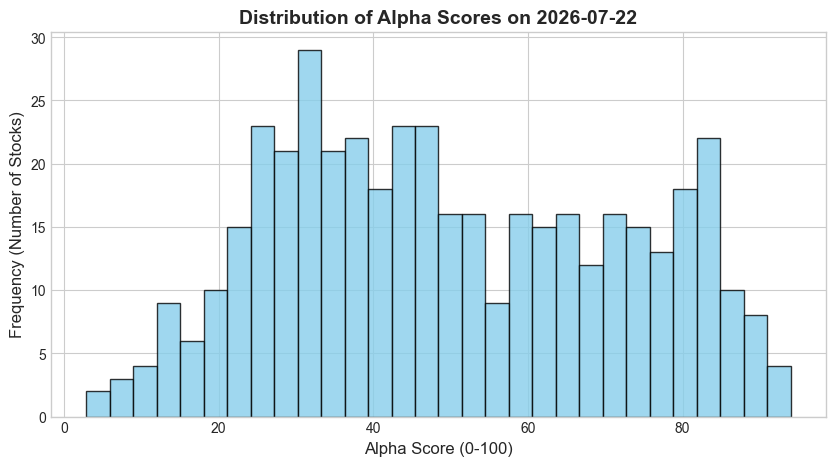

In [16]:
# Cell: Plot Score Distributions
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(ranking["alpha_score"], bins=30, color='skyblue', edgecolor='black', alpha=0.8)
ax.set_title(f"Distribution of Alpha Scores on {latest_date.strftime('%Y-%m-%d') if hasattr(latest_date, 'strftime') else latest_date}", fontsize=14, weight='bold')
ax.set_xlabel("Alpha Score (0-100)", fontsize=12)
ax.set_ylabel("Frequency (Number of Stocks)", fontsize=12)
plt.show()

## 1. Advanced Portfolio & Alpha Visualizations

Dưới đây là một bộ trực quan hóa đa chiều giúp phân tích động lượng (momentum), cấu phần nguồn alpha, rủi ro biến động, hệ số tương quan và cơ cấu danh mục để đưa ra quyết định đầu tư tối ưu.

### 1.1 Top 20 Alpha Scores
Biểu đồ cột hiển thị mức độ chênh lệch điểm số Alpha giữa các mã hàng đầu.

In [17]:
# Cell: Interactive Top Alpha Bar Chart
from src.reporting.chart_factory import top_alpha_bar_chart

fig_bar = top_alpha_bar_chart(ranking, top_n=20)
fig_bar.show()

### 1.2 Alpha Factor Breakdown Heatmap
Bản đồ nhiệt cấu phần điểm số giúp kiểm tra chất lượng điểm Alpha. Bạn có thể nhanh chóng xem mã cổ phiếu có điểm cao là nhờ dòng tiền (volume), động lượng (momentum), xu hướng giá (trend), hay do biến động thấp (volatility contraction).

In [18]:
# Cell: Interactive Alpha Factor Breakdown Heatmap
from src.reporting.chart_factory import alpha_factor_heatmap

fig_heatmap = alpha_factor_heatmap(ranking, top_n=20)
fig_heatmap.show()

### 1.3 Alpha Score vs Volatility Scatter Plot
Biểu đồ phân tán so sánh điểm Alpha với độ biến động (Annualized Volatility). Cổ phiếu lý tưởng nằm ở góc **trên-trái** (Alpha cao, Biến động thấp). Đường kẻ đỏ thể hiện mức biến động trung vị của toàn thị trường, đường kẻ xanh thể hiện ngưỡng Alpha mạnh (>=75).

In [19]:
# Cell: Interactive Alpha vs Volatility Scatter Plot
from src.reporting.chart_factory import alpha_vs_volatility_chart

fig_vol = alpha_vs_volatility_chart(scored_with_beta, date=latest_date)
fig_vol.show()

### 1.4 Alpha Score vs Beta Scatter Plot
So sánh điểm số Alpha với hệ số Beta (đo lường độ nhạy so với chỉ số VNINDEX). Giúp lọc ra những cổ phiếu có Alpha cao thực sự (alpha đặc trưng của doanh nghiệp) thay vì chỉ có Alpha giả tạo nhờ đòn bẩy thị trường (high beta).

In [20]:
# Cell: Interactive Alpha vs Beta Scatter Plot
from src.reporting.chart_factory import alpha_vs_beta_chart

fig_beta = alpha_vs_beta_chart(scored_with_beta, date=latest_date)
fig_beta.show()

### 1.5 Correlation Heatmap of Top 15 Alpha Stocks
Bản đồ tương quan Pearson dựa trên tỷ suất sinh lợi 120 phiên gần nhất của 15 cổ phiếu xếp hạng Alpha cao nhất. Một danh mục gồm các cổ phiếu có tương quan chéo thấp sẽ mang lại hiệu quả đa dạng hóa rủi ro tốt nhất.

In [21]:
# Cell: Correlation Heatmap of Top Holdings
from src.reporting.chart_factory import correlation_heatmap

top_symbols = ranking["symbol"].head(15).tolist()
recent_df = scored_with_beta[scored_with_beta["symbol"].isin(top_symbols)].copy()
recent_df = recent_df.sort_values(["symbol", "date"])
recent_df = recent_df.groupby("symbol").tail(120)

return_matrix = recent_df.pivot_table(index="date", columns="symbol", values="return_1d", aggfunc="last")
corr_matrix = return_matrix.corr(method="pearson")

fig_corr = correlation_heatmap(corr_matrix, title="Correlation Heatmap of Top 15 Alpha Stocks (Last 120 Trading Days)")
fig_corr.show()

### 1.6 Historical Cumulative Returns of Top 5 Alpha Stocks
Đồ thị so sánh tỷ suất sinh lợi lũy kế của 5 cổ phiếu đứng đầu (được quy về mốc giá trị 100 tại ngày đầu tiên của chuỗi 120 phiên gần nhất). Giúp kiểm chứng độ bền bỉ và xu hướng giá của các siêu cổ phiếu.

In [22]:
# Cell: Historical Cumulative Returns of Top 5 Alpha Stocks
import plotly.express as px

top_5_symbols = ranking["symbol"].head(5).tolist()
recent_stock_df = scored_with_beta[scored_with_beta["symbol"].isin(top_5_symbols)].copy()
recent_stock_df = recent_stock_df.groupby("symbol").tail(120)

cum_returns_list = []
for sym, gp in recent_stock_df.groupby("symbol"):
    gp = gp.sort_values("date").copy()
    gp["cum_return"] = (1.0 + gp["return_1d"].fillna(0.0)).cumprod() * 100
    cum_returns_list.append(gp[["date", "symbol", "cum_return"]])

cum_returns_df = pd.concat(cum_returns_list)
fig_cum = px.line(
    cum_returns_df,
    x="date",
    y="cum_return",
    color="symbol",
    title="Historical Cumulative Returns of Top 5 Alpha Stocks (Reindexed to 100 over Last 120 Trading Days)",
    labels={"cum_return": "Cumulative Return", "date": "Date"}
)
fig_cum.show()

In [ ]:
# Cell: Export Reports
# Writes to notebooks/outputs/, NOT reports/ (AUDIT_NOTEBOOKS_REPORT.md OPEN_AUTO #3).
#
# reports/daily_alpha_ranking.csv and reports/top_watchlist.csv are owned by
# scripts/run_alpha_scoring.py, which runs nightly, writes them atomically, and
# records their lineage in reports/alpha_scoring_metadata.json. This cell used
# to overwrite both by hand with a plain to_csv(): on 2026-07-23 it ran two
# hours after the pipeline and left top_watchlist.csv with a different schema
# (no `alpha_score_shadow_v1`, extra `rolling_beta_60d`) while the sidecar
# still claimed to describe it.
#
# `ranking` here is also NOT the same object the pipeline exports -- it lacks
# the v1 shadow column that SCORE_V2_REPORT.md's live v2-vs-v1 comparison
# depends on. Keep the two side by side rather than letting one clobber the other.
from src.data.loaders import save_csv_atomic

notebook_outputs_dir = Path("notebooks/outputs")
notebook_outputs_dir.mkdir(parents=True, exist_ok=True)

save_csv_atomic(ranking, notebook_outputs_dir / "daily_alpha_ranking.csv")
save_csv_atomic(ranking.head(20), notebook_outputs_dir / "top_watchlist.csv")
print(f"Exported notebook copies to {notebook_outputs_dir.resolve()}")
print("Pipeline-owned reports/ versions left untouched -- regenerate them with "
      "`python scripts/run_alpha_scoring.py`.")